In [1]:
# ============================================
# FLIPKART E-COMMERCE ANALYTICS PROJECT
# STEP 1: IMPORT LIBRARIES
# ============================================

!pip install faker

import pandas as pd
import numpy as np
import random

from faker import Faker

print("Libraries imported successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 8.9 MB/s  0:00:00
Libraries imported successfully!


In [2]:
# ============================================
# STEP 2: SETUP
# ============================================

fake = Faker("en_IN")

np.random.seed(42)
random.seed(42)

N = 50000

print(f"Target records: {N:,}")

Target records: 50,000


In [3]:
# ============================================
# STEP 3: INDIAN GEOGRAPHY
# ============================================

locations = {
    "Andhra Pradesh": ["Vijayawada", "Visakhapatnam", "Guntur", "Tirupati"],
    "Telangana": ["Hyderabad", "Warangal", "Nizamabad", "Karimnagar"],
    "Karnataka": ["Bengaluru", "Mysuru", "Mangaluru", "Hubballi"],
    "Tamil Nadu": ["Chennai", "Coimbatore", "Madurai", "Salem"],
    "Maharashtra": ["Mumbai", "Pune", "Nagpur", "Nashik"],
    "Delhi": ["New Delhi", "Delhi"],
    "Uttar Pradesh": ["Lucknow", "Kanpur", "Agra", "Noida"],
    "West Bengal": ["Kolkata", "Durgapur", "Siliguri"],
    "Gujarat": ["Ahmedabad", "Surat", "Vadodara"],
    "Rajasthan": ["Jaipur", "Jodhpur", "Udaipur"],
    "Kerala": ["Kochi", "Thiruvananthapuram", "Kozhikode"],
    "Odisha": ["Bhubaneswar", "Cuttack", "Rourkela"]
}

states = list(locations.keys())

region_map = {
    "Andhra Pradesh": "South",
    "Telangana": "South",
    "Karnataka": "South",
    "Tamil Nadu": "South",
    "Kerala": "South",
    "Maharashtra": "West",
    "Gujarat": "West",
    "Rajasthan": "West",
    "Delhi": "North",
    "Uttar Pradesh": "North",
    "West Bengal": "East",
    "Odisha": "East"
}

print("Geography created.")

Geography created.


In [4]:
# ============================================
# STEP 4: PRODUCT CATALOG
# ============================================

products = {
    "Electronics": {
        "subcategories": ["Smartphones", "Laptops", "Headphones", "Smartwatches"],
        "products": [
            "Samsung Galaxy Smartphone",
            "Apple iPhone",
            "OnePlus Smartphone",
            "HP Laptop",
            "Lenovo Laptop",
            "Sony Headphones",
            "Boat Wireless Earbuds",
            "Noise Smartwatch"
        ],
        "price_range": (800, 120000)
    },

    "Fashion": {
        "subcategories": ["Men", "Women", "Footwear", "Accessories"],
        "products": [
            "Men's Casual Shirt",
            "Women's Kurti",
            "Men's Jeans",
            "Women's Dress",
            "Running Shoes",
            "Formal Shoes",
            "Handbag",
            "Backpack"
        ],
        "price_range": (300, 8000)
    },

    "Home & Kitchen": {
        "subcategories": ["Kitchen", "Furniture", "Appliances", "Decor"],
        "products": [
            "Mixer Grinder",
            "Electric Kettle",
            "Office Chair",
            "Bedsheet Set",
            "Non-Stick Cookware",
            "Table Lamp",
            "Storage Organizer",
            "Dining Set"
        ],
        "price_range": (500, 25000)
    },

    "Beauty": {
        "subcategories": ["Skincare", "Makeup", "Haircare", "Fragrance"],
        "products": [
            "Face Moisturizer",
            "Sunscreen",
            "Lipstick",
            "Shampoo",
            "Hair Serum",
            "Perfume",
            "Face Wash",
            "Body Lotion"
        ],
        "price_range": (200, 5000)
    },

    "Books": {
        "subcategories": ["Education", "Fiction", "Business", "Technology"],
        "products": [
            "Python Programming Book",
            "Data Science Handbook",
            "Business Strategy Book",
            "Novel Collection",
            "Machine Learning Guide",
            "SQL Complete Reference",
            "Finance Book",
            "Self Improvement Book"
        ],
        "price_range": (150, 2500)
    },

    "Sports": {
        "subcategories": ["Fitness", "Cricket", "Football", "Outdoor"],
        "products": [
            "Cricket Bat",
            "Cricket Shoes",
            "Football",
            "Yoga Mat",
            "Dumbbell Set",
            "Tennis Racket",
            "Sports Bag",
            "Fitness Tracker"
        ],
        "price_range": (300, 12000)
    }
}

print("Product catalog created.")
print("Categories:", list(products.keys()))

Product catalog created.
Categories: ['Electronics', 'Fashion', 'Home & Kitchen', 'Beauty', 'Books', 'Sports']


In [5]:
# ============================================
# STEP 5: CREATE CUSTOMER DATA
# ============================================

N_CUSTOMERS = 12000

customer_ids = [f"CUST{i:05d}" for i in range(1, N_CUSTOMERS + 1)]

customers = pd.DataFrame({
    "Customer_ID": customer_ids,
    "Customer_Name": [fake.name() for _ in range(N_CUSTOMERS)],
    "Age": np.random.randint(18, 65, N_CUSTOMERS),
    "Gender": np.random.choice(
        ["Male", "Female"],
        N_CUSTOMERS,
        p=[0.55, 0.45]
    )
})

# Define raw probabilities
raw_probabilities = [
    0.08, 0.07, 0.09, 0.08,
    0.12, 0.08, 0.12, 0.08,
    0.08, 0.07, 0.07, 0.04
]

# Normalize probabilities to sum to 1
sum_probabilities = sum(raw_probabilities)
normalized_probabilities = [p / sum_probabilities for p in raw_probabilities]

# Assign states and cities
customers["State"] = np.random.choice(
    states,
    N_CUSTOMERS,
    p=normalized_probabilities
)

customers["City"] = customers["State"].apply(
    lambda x: random.choice(locations[x])
)

customers["Region"] = customers["State"].map(region_map)

print("Customers created:", len(customers))
display(customers.head())

Customers created: 12000


,Customer_ID,Customer_Name,Age,Gender,State,City,Region
0,CUST00001,Vritti Hayer,56,Female,Delhi,New Delhi,North
1,CUST00002,Wriddhish Kala,46,Male,Telangana,Hyderabad,South
2,CUST00003,Mitesh Narang,32,Female,Rajasthan,Udaipur,West
3,CUST00004,Yamini Goswami,60,Male,Tamil Nadu,Madurai,South
4,CUST00005,Indira Kapoor,25,Male,Gujarat,Ahmedabad,West


In [6]:
# ============================================
# STEP 6: CREATE ORDERS
# ============================================

orders = pd.DataFrame({
    "Order_ID": [f"ORD{i:06d}" for i in range(1, N + 1)],

    "Customer_ID": np.random.choice(
        customer_ids,
        N
    ),

    "Order_Date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2024-01-01", "2025-12-31"),
            N
        )
    )
})

# Connect customer information
orders = orders.merge(
    customers,
    on="Customer_ID",
    how="left"
)

print("Orders created:", len(orders))
display(orders.head())

Orders created: 50000


,Order_ID,Customer_ID,Order_Date,Customer_Name,Age,Gender,State,City,Region
0,ORD000001,CUST01269,2024-06-19,Samesh Mann,52,Male,Andhra Pradesh,Tirupati,South
1,ORD000002,CUST09683,2025-04-18,Yashoda Gandhi,18,Male,Telangana,Warangal,South
2,ORD000003,CUST05562,2025-02-25,Anika Sani,23,Female,Maharashtra,Nagpur,West
3,ORD000004,CUST06046,2025-06-16,Jeremiah Mistry,22,Female,West Bengal,Durgapur,East
4,ORD000005,CUST11272,2024-10-12,Mahika Ahuja,20,Male,Rajasthan,Jaipur,West


In [7]:
# ============================================
# STEP 7: ADD PRODUCT INFORMATION
# ============================================

categories = list(products.keys())

orders["Category"] = np.random.choice(
    categories,
    N,
    p=[0.28, 0.25, 0.18, 0.10, 0.10, 0.09]
)

orders["Sub_Category"] = orders["Category"].apply(
    lambda x: random.choice(products[x]["subcategories"])
)

orders["Product_Name"] = orders["Category"].apply(
    lambda x: random.choice(products[x]["products"])
)

# Create Product IDs based on product name
product_names = orders["Product_Name"].unique()

product_id_map = {
    product: f"PROD{i:04d}"
    for i, product in enumerate(product_names, 1)
}

orders["Product_ID"] = orders["Product_Name"].map(product_id_map)

print("Products assigned successfully.")

display(
    orders[
        [
            "Order_ID",
            "Customer_ID",
            "Category",
            "Sub_Category",
            "Product_Name",
            "Product_ID"
        ]
    ].head()
)

Products assigned successfully.


,Order_ID,Customer_ID,Category,Sub_Category,Product_Name,Product_ID
0,ORD000001,CUST01269,Sports,Fitness,Football,PROD0001
1,ORD000002,CUST09683,Home & Kitchen,Decor,Non-Stick Cookware,PROD0002
2,ORD000003,CUST05562,Fashion,Women,Formal Shoes,PROD0003
3,ORD000004,CUST06046,Electronics,Smartphones,Boat Wireless Earbuds,PROD0004
4,ORD000005,CUST11272,Beauty,Fragrance,Sunscreen,PROD0005


In [8]:
# ============================================
# STEP 8: PRICE & QUANTITY
# ============================================

def generate_price(category):
    low, high = products[category]["price_range"]
    return round(np.random.uniform(low, high), 2)

orders["Unit_Price"] = orders["Category"].apply(generate_price)

orders["Quantity"] = np.random.choice(
    [1, 2, 3, 4, 5],
    N,
    p=[0.55, 0.25, 0.12, 0.05, 0.03]
)

orders["Discount_Percent"] = np.round(
    np.random.choice(
        [0, 5, 10, 15, 20, 25, 30],
        N,
        p=[0.10, 0.20, 0.25, 0.20, 0.12, 0.08, 0.05]
    ),
    2
)

# Gross amount
orders["Gross_Amount"] = (
    orders["Unit_Price"] *
    orders["Quantity"]
)

# Discount amount
orders["Discount_Amount"] = (
    orders["Gross_Amount"] *
    orders["Discount_Percent"] / 100
)

# Final sales amount
orders["Sales_Amount"] = (
    orders["Gross_Amount"] -
    orders["Discount_Amount"]
)

print("Pricing generated.")
display(
    orders[
        [
            "Unit_Price",
            "Quantity",
            "Discount_Percent",
            "Gross_Amount",
            "Sales_Amount"
        ]
    ].head()
)

Pricing generated.


,Unit_Price,Quantity,Discount_Percent,Gross_Amount,Sales_Amount
0,10443.45,2,20,20886.90,16709.520
1,17322.29,2,5,34644.58,32912.351
2,983.62,1,20,983.62,786.896
3,87143.38,2,15,174286.76,148143.746
4,2093.62,1,20,2093.62,1674.896


In [9]:
# ============================================
# STEP 9: COST & PROFIT
# ============================================

# Cost is between 60% and 90% of selling price
cost_percentage = np.random.uniform(
    0.60,
    0.90,
    N
)

orders["Cost_Amount"] = (
    orders["Sales_Amount"] *
    cost_percentage
)

orders["Profit"] = (
    orders["Sales_Amount"] -
    orders["Cost_Amount"]
)

orders["Profit"] = orders["Profit"].round(2)

print("Profit calculated.")

display(
    orders[
        [
            "Sales_Amount",
            "Cost_Amount",
            "Profit"
        ]
    ].head()
)

Profit calculated.


,Sales_Amount,Cost_Amount,Profit
0,16709.520,11491.175266,5218.34
1,32912.351,24429.937027,8482.41
2,786.896,693.810121,93.09
3,148143.746,126315.985346,21827.76
4,1674.896,1119.935412,554.96


In [10]:
# ============================================
# STEP 10: PAYMENT & DELIVERY
# ============================================

orders["Payment_Method"] = np.random.choice(
    [
        "UPI",
        "Credit Card",
        "Debit Card",
        "Cash on Delivery",
        "Net Banking",
        "Wallet"
    ],
    N,
    p=[0.35, 0.18, 0.15, 0.18, 0.08, 0.06]
)

orders["Delivery_Days"] = np.random.choice(
    [1, 2, 3, 4, 5, 6, 7],
    N,
    p=[0.05, 0.15, 0.25, 0.25, 0.15, 0.10, 0.05]
)

orders["Order_Status"] = np.random.choice(
    [
        "Delivered",
        "Returned",
        "Cancelled"
    ],
    N,
    p=[0.88, 0.09, 0.03]
)

print("Order status and payment information added.")

Order status and payment information added.


In [11]:
# ============================================
# STEP 11: RETURN ANALYSIS DATA
# ============================================

orders["Return_Flag"] = (
    orders["Order_Status"] == "Returned"
).astype(int)

# Return date only for returned orders
orders["Return_Date"] = pd.NaT

returned_mask = orders["Return_Flag"] == 1

orders.loc[returned_mask, "Return_Date"] = (
    orders.loc[returned_mask, "Order_Date"]
    + pd.to_timedelta(
        np.random.randint(3, 31, returned_mask.sum()),
        unit="D"
    )
)

# Return reasons
return_reasons = [
    "Damaged Product",
    "Wrong Product",
    "Product Quality",
    "Size/Fit Issue",
    "Changed Mind",
    "Late Delivery",
    "Other"
]

orders["Return_Reason"] = np.nan

orders.loc[returned_mask, "Return_Reason"] = np.random.choice(
    return_reasons,
    returned_mask.sum(),
    p=[0.15, 0.12, 0.20, 0.18, 0.15, 0.10, 0.10]
)

# Refund amount
orders["Refund_Amount"] = np.where(
    orders["Return_Flag"] == 1,
    orders["Sales_Amount"],
    0
)

# Return processing cost
orders["Return_Cost"] = np.where(
    orders["Return_Flag"] == 1,
    orders["Sales_Amount"] * np.random.uniform(
        0.03, 0.12, N
    ),
    0
)

orders["Refund_Amount"] = orders["Refund_Amount"].round(2)
orders["Return_Cost"] = orders["Return_Cost"].round(2)

print("Return information generated.")

Return information generated.


/tmp/ipykernel_642/1826160065.py:35: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['Size/Fit Issue' 'Size/Fit Issue' 'Size/Fit Issue' ... 'Damaged Product'
 'Other' 'Product Quality']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  orders.loc[returned_mask, "Return_Reason"] = np.random.choice(


In [12]:
# ============================================
# STEP 12: CUSTOMER RATINGS
# ============================================

orders["Customer_Rating"] = np.random.choice(
    [1, 2, 3, 4, 5],
    N,
    p=[0.05, 0.08, 0.17, 0.35, 0.35]
)

print("Ratings added.")

Ratings added.


In [13]:
# ============================================
# STEP 13: NET SALES & NET PROFIT
# ============================================

orders["Net_Sales"] = (
    orders["Sales_Amount"] -
    orders["Refund_Amount"]
)

orders["Net_Profit"] = (
    orders["Profit"] -
    orders["Return_Cost"]
)

orders["Net_Sales"] = orders["Net_Sales"].round(2)
orders["Net_Profit"] = orders["Net_Profit"].round(2)

print("Net metrics calculated.")

Net metrics calculated.


In [14]:
# ============================================
# STEP 14: FINAL DATASET
# ============================================

print("Dataset Shape:", orders.shape)

print("\nColumns:")
print(orders.columns.tolist())

print("\nFirst 5 records:")
display(orders.head())

print("\nOrder Status:")
display(orders["Order_Status"].value_counts())

print("\nReturn Rate:")
return_rate = orders["Return_Flag"].mean() * 100
print(f"{return_rate:.2f}%")

print("\nTotal Sales:")
print(f"₹{orders['Sales_Amount'].sum():,.2f}")

print("\nTotal Profit:")
print(f"₹{orders['Profit'].sum():,.2f}")

Dataset Shape: (50000, 32)

Columns:
['Order_ID', 'Customer_ID', 'Order_Date', 'Customer_Name', 'Age', 'Gender', 'State', 'City', 'Region', 'Category', 'Sub_Category', 'Product_Name', 'Product_ID', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Gross_Amount', 'Discount_Amount', 'Sales_Amount', 'Cost_Amount', 'Profit', 'Payment_Method', 'Delivery_Days', 'Order_Status', 'Return_Flag', 'Return_Date', 'Return_Reason', 'Refund_Amount', 'Return_Cost', 'Customer_Rating', 'Net_Sales', 'Net_Profit']

First 5 records:


,Order_ID,Customer_ID,Order_Date,Customer_Name,Age,Gender,State,City,Region,Category,...,Delivery_Days,Order_Status,Return_Flag,Return_Date,Return_Reason,Refund_Amount,Return_Cost,Customer_Rating,Net_Sales,Net_Profit
0,ORD000001,CUST01269,2024-06-19,Samesh Mann,52,Male,Andhra Pradesh,Tirupati,South,Sports,...,5,Delivered,0,NaT,NaN,0.0,0.0,3,16709.52,5218.34
1,ORD000002,CUST09683,2025-04-18,Yashoda Gandhi,18,Male,Telangana,Warangal,South,Home & Kitchen,...,5,Delivered,0,NaT,NaN,0.0,0.0,4,32912.35,8482.41
2,ORD000003,CUST05562,2025-02-25,Anika Sani,23,Female,Maharashtra,Nagpur,West,Fashion,...,2,Delivered,0,NaT,NaN,0.0,0.0,5,786.90,93.09
3,ORD000004,CUST06046,2025-06-16,Jeremiah Mistry,22,Female,West Bengal,Durgapur,East,Electronics,...,4,Delivered,0,NaT,NaN,0.0,0.0,5,148143.75,21827.76
4,ORD000005,CUST11272,2024-10-12,Mahika Ahuja,20,Male,Rajasthan,Jaipur,West,Beauty,...,3,Delivered,0,NaT,NaN,0.0,0.0,5,1674.90,554.96



Order Status:


,count
Order_Status,
Delivered,44036
Returned,4545
Cancelled,1419



Return Rate:
9.09%

Total Sales:
₹1,631,612,684.03

Total Profit:
₹409,223,943.63


In [15]:
# ============================================
# STEP 15.1: CHECK DATA TYPES
# ============================================

print("DATA TYPES")
print("=" * 60)

display(
    pd.DataFrame({
        "Column": orders.columns,
        "Data_Type": orders.dtypes.astype(str),
        "Missing_Count": orders.isnull().sum().values,
        "Unique_Values": orders.nunique().values
    })
)

DATA TYPES


,Column,Data_Type,Missing_Count,Unique_Values
Order_ID,Order_ID,object,0,50000
Customer_ID,Customer_ID,object,0,11837
Order_Date,Order_Date,datetime64[ns],0,731
Customer_Name,Customer_Name,object,0,11584
Age,Age,int64,0,47
Gender,Gender,object,0,2
State,State,object,0,12
City,City,object,0,41
Region,Region,object,0,4
Category,Category,object,0,6


In [16]:
# ============================================
# STEP 15.2: DUPLICATE CHECK
# ============================================

duplicate_orders = orders["Order_ID"].duplicated().sum()

print(f"Duplicate Order IDs: {duplicate_orders:,}")

if duplicate_orders == 0:
    print("✅ No duplicate orders found.")
else:
    print("⚠️ Duplicate orders found.")

Duplicate Order IDs: 0
✅ No duplicate orders found.


In [17]:
# ============================================
# STEP 15.3: MISSING VALUE ANALYSIS
# ============================================

missing = (
    orders.isnull()
    .sum()
    .reset_index()
)

missing.columns = ["Column", "Missing_Count"]

missing["Missing_Percentage"] = (
    missing["Missing_Count"] /
    len(orders) * 100
)

missing = missing.sort_values(
    "Missing_Count",
    ascending=False
)

display(missing)

,Column,Missing_Count,Missing_Percentage
25,Return_Date,45455,90.91
26,Return_Reason,45455,90.91
0,Order_ID,0,0.00
1,Customer_ID,0,0.00
4,Age,0,0.00
5,Gender,0,0.00
2,Order_Date,0,0.00
3,Customer_Name,0,0.00
8,Region,0,0.00
9,Category,0,0.00


In [18]:
# ============================================
# STEP 16.1: NEGATIVE VALUE CHECK
# ============================================

numeric_columns = [
    "Age",
    "Quantity",
    "Unit_Price",
    "Discount_Percent",
    "Gross_Amount",
    "Discount_Amount",
    "Sales_Amount",
    "Cost_Amount",
    "Profit",
    "Delivery_Days",
    "Refund_Amount",
    "Return_Cost",
    "Net_Sales",
    "Net_Profit",
    "Customer_Rating"
]

negative_values = {}

for col in numeric_columns:
    negative_values[col] = (orders[col] < 0).sum()

negative_check = pd.Series(
    negative_values,
    name="Negative_Count"
)

display(negative_check.to_frame())

,Negative_Count
Age,0
Quantity,0
Unit_Price,0
Discount_Percent,0
Gross_Amount,0
Discount_Amount,0
Sales_Amount,0
Cost_Amount,0
Profit,0
Delivery_Days,0


In [19]:
# ============================================
# STEP 16.2: BUSINESS RULE VALIDATION
# ============================================

print("Age outside 18-65:",
      ((orders["Age"] < 18) | (orders["Age"] > 65)).sum())

print("Quantity <= 0:",
      (orders["Quantity"] <= 0).sum())

print("Discount outside 0-30%:",
      ((orders["Discount_Percent"] < 0) |
       (orders["Discount_Percent"] > 30)).sum())

print("Rating outside 1-5:",
      ((orders["Customer_Rating"] < 1) |
       (orders["Customer_Rating"] > 5)).sum())

print("Delivery days <= 0:",
      (orders["Delivery_Days"] <= 0).sum())

Age outside 18-65: 0
Quantity <= 0: 0
Discount outside 0-30%: 0
Rating outside 1-5: 0
Delivery days <= 0: 0


In [20]:
# ============================================
# STEP 17: VALIDATE SALES CALCULATIONS
# ============================================

calculated_gross = (
    orders["Unit_Price"] *
    orders["Quantity"]
)

gross_difference = (
    orders["Gross_Amount"] -
    calculated_gross
).abs()

print(
    "Incorrect Gross Amount:",
    (gross_difference > 0.01).sum()
)

calculated_sales = (
    orders["Gross_Amount"] -
    orders["Discount_Amount"]
)

sales_difference = (
    orders["Sales_Amount"] -
    calculated_sales
).abs()

print(
    "Incorrect Sales Amount:",
    (sales_difference > 0.01).sum()
)

Incorrect Gross Amount: 0
Incorrect Sales Amount: 0


In [21]:
# ============================================
# STEP 18: VALIDATE PROFIT
# ============================================

calculated_profit = (
    orders["Sales_Amount"] -
    orders["Cost_Amount"]
)

profit_difference = (
    orders["Profit"] -
    calculated_profit
).abs()

print(
    "Incorrect Profit Records:",
    (profit_difference > 0.01).sum()
)

Incorrect Profit Records: 0


In [22]:
# ============================================
# STEP 19: RETURN VALIDATION
# ============================================

# Returned orders should have Return_Flag = 1
returned_status_check = (
    (orders["Order_Status"] == "Returned") &
    (orders["Return_Flag"] != 1)
).sum()

# Non-returned orders should have Return_Flag = 0
non_returned_status_check = (
    (orders["Order_Status"] != "Returned") &
    (orders["Return_Flag"] != 0)
).sum()

print(
    "Returned status mismatch:",
    returned_status_check
)

print(
    "Non-returned status mismatch:",
    non_returned_status_check
)

Returned status mismatch: 0
Non-returned status mismatch: 0


In [23]:
# ============================================
# STEP 19.1: RETURN DATE VALIDATION
# ============================================

invalid_return_dates = (
    (orders["Return_Flag"] == 1) &
    (
        orders["Return_Date"].isna() |
        (orders["Return_Date"] <= orders["Order_Date"])
    )
).sum()

print(
    "Invalid return dates:",
    invalid_return_dates
)

Invalid return dates: 0


In [25]:
# ============================================
# STEP 20: CREATE CLEAN DATASET
# ============================================

df_clean = orders.copy()

print("Original records:", len(orders))
print("Clean dataset records:", len(df_clean))

Original records: 50000
Clean dataset records: 50000


In [26]:
# ============================================
# STEP 20.1: STANDARDIZE COLUMN NAMES
# ============================================

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df_clean.columns.tolist())

['order_id', 'customer_id', 'order_date', 'customer_name', 'age', 'gender', 'state', 'city', 'region', 'category', 'sub_category', 'product_name', 'product_id', 'unit_price', 'quantity', 'discount_percent', 'gross_amount', 'discount_amount', 'sales_amount', 'cost_amount', 'profit', 'payment_method', 'delivery_days', 'order_status', 'return_flag', 'return_date', 'return_reason', 'refund_amount', 'return_cost', 'customer_rating', 'net_sales', 'net_profit']


In [27]:
# ============================================
# STEP 21: FEATURE ENGINEERING
# ============================================

df_clean["order_year"] = df_clean["order_date"].dt.year

df_clean["order_month"] = df_clean["order_date"].dt.month

df_clean["order_month_name"] = (
    df_clean["order_date"]
    .dt.strftime("%B")
)

df_clean["order_quarter"] = (
    "Q" +
    df_clean["order_date"].dt.quarter.astype(str)
)

df_clean["order_year_month"] = (
    df_clean["order_date"]
    .dt.to_period("M")
    .astype(str)
)

# Profit margin
df_clean["profit_margin"] = np.where(
    df_clean["sales_amount"] > 0,
    (df_clean["profit"] / df_clean["sales_amount"]) * 100,
    0
)

# Return rate indicator
df_clean["return_rate"] = df_clean["return_flag"]

print("Feature engineering completed.")

Feature engineering completed.


In [29]:
# ============================================
# STEP 22: FINAL QUALITY SUMMARY
# ============================================

print("=" * 60)
print("FINAL DATA QUALITY SUMMARY")
print("=" * 60)

print(f"Total Orders       : {len(df_clean):,}")
print(f"Total Customers    : {df_clean['customer_id'].nunique():,}")
print(f"Total Products     : {df_clean['product_id'].nunique():,}")
print(f"Categories         : {df_clean['category'].nunique()}")
print(f"States             : {df_clean['state'].nunique()}")

print(
    f"Total Sales        : ₹{df_clean['sales_amount'].sum():,.2f}"
)

print(
    f"Total Profit       : ₹{df_clean['profit'].sum():,.2f}"
)

print(
    f"Total Returns      : {df_clean['return_flag'].sum():,}"
)

print(
    f"Return Rate        : {df_clean['return_flag'].mean()*100:.2f}%"
)

print(
    f"Total Refunds      : ₹{df_clean['refund_amount'].sum():,.2f}"
)

print(
    f"Total Net Sales    : ₹{df_clean['net_sales'].sum():,.2f}"
)

print(
    f"Total Net Profit   : ₹{df_clean['net_profit'].sum():,.2f}"
)

FINAL DATA QUALITY SUMMARY
Total Orders       : 50,000
Total Customers    : 11,837
Total Products     : 48
Categories         : 6
States             : 12
Total Sales        : ₹1,631,612,684.03
Total Profit       : ₹409,223,943.63
Total Returns      : 4,545
Return Rate        : 9.09%
Total Refunds      : ₹151,875,350.49
Total Net Sales    : ₹1,479,737,333.87
Total Net Profit   : ₹397,812,380.89


In [30]:
# ============================================
# STEP 23: EXPORT CLEAN DATASET
# ============================================

output_file = "flipkart_ecommerce_cleaned.csv"

df_clean.to_csv(
    output_file,
    index=False
)

print(f"✅ Dataset exported: {output_file}")

✅ Dataset exported: flipkart_ecommerce_cleaned.csv


In [31]:
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# ============================================
# STEP 24: CREATE SQL DATABASE
# ============================================

import sqlite3

# Create SQLite database
conn = sqlite3.connect("flipkart_analytics.db")

# Load Pandas DataFrame into SQL table
df_clean.to_sql(
    "orders",
    conn,
    if_exists="replace",
    index=False
)

print("✅ SQLite database created successfully!")
print("✅ Table 'orders' created successfully!")

✅ SQLite database created successfully!
✅ Table 'orders' created successfully!


In [33]:
# ============================================
# STEP 25: VERIFY SQL TABLE
# ============================================

query = """
SELECT *
FROM orders
LIMIT 5;
"""

sql_result = pd.read_sql_query(query, conn)

display(sql_result)

,order_id,customer_id,order_date,customer_name,age,gender,state,city,region,category,...,customer_rating,net_sales,net_profit,order_year,order_month,order_month_name,order_quarter,order_year_month,profit_margin,return_rate
0,ORD000001,CUST01269,2024-06-19 00:00:00,Samesh Mann,52,Male,Andhra Pradesh,Tirupati,South,Sports,...,3,16709.52,5218.34,2024,6,June,Q2,2024-06,31.229742,0
1,ORD000002,CUST09683,2025-04-18 00:00:00,Yashoda Gandhi,18,Male,Telangana,Warangal,South,Home & Kitchen,...,4,32912.35,8482.41,2025,4,April,Q2,2025-04,25.772726,0
2,ORD000003,CUST05562,2025-02-25 00:00:00,Anika Sani,23,Female,Maharashtra,Nagpur,West,Fashion,...,5,786.90,93.09,2025,2,February,Q1,2025-02,11.830026,0
3,ORD000004,CUST06046,2025-06-16 00:00:00,Jeremiah Mistry,22,Female,West Bengal,Durgapur,East,Electronics,...,5,148143.75,21827.76,2025,6,June,Q2,2025-06,14.734176,0
4,ORD000005,CUST11272,2024-10-12 00:00:00,Mahika Ahuja,20,Male,Rajasthan,Jaipur,West,Beauty,...,5,1674.90,554.96,2024,10,October,Q4,2024-10,33.133998,0


In [34]:
query = """
SELECT COUNT(*) AS total_orders
FROM orders;
"""

pd.read_sql_query(query, conn)

,total_orders
0,50000


In [35]:
query = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT customer_id) AS total_customers,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit,
    SUM(net_sales) AS net_sales,
    SUM(net_profit) AS net_profit
FROM orders;
"""

display(pd.read_sql_query(query, conn))

,total_orders,total_customers,total_sales,total_profit,net_sales,net_profit
0,50000,11837,1.631613e+09,4.092239e+08,1.479737e+09,3.978124e+08


In [36]:
query = """
SELECT
    category,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit,
    ROUND(
        SUM(profit) * 100.0 / SUM(sales_amount),
        2
    ) AS profit_margin
FROM orders
GROUP BY category
ORDER BY total_sales DESC;
"""

display(pd.read_sql_query(query, conn))

,category,total_orders,total_sales,total_profit,profit_margin
0,Electronics,14023,1.299670e+09,3.261527e+08,25.10
1,Home & Kitchen,9004,1.774239e+08,4.449349e+07,25.08
2,Fashion,12597,8.123395e+07,2.026906e+07,24.95
3,Sports,4508,4.338262e+07,1.085848e+07,25.03
4,Beauty,4899,1.948940e+07,4.871099e+06,24.99
5,Books,4969,1.041314e+07,2.579085e+06,24.77


In [37]:
query = """
SELECT
    order_year_month,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit,
    COUNT(DISTINCT order_id) AS total_orders
FROM orders
GROUP BY order_year_month
ORDER BY order_year_month;
"""

monthly_sales = pd.read_sql_query(query, conn)

display(monthly_sales)

,order_year_month,total_sales,total_profit,total_orders
0,2024-01,7.097409e+07,18167647.25,2145
1,2024-02,5.964771e+07,15005161.53,1915
2,2024-03,7.017580e+07,18040746.02,2148
3,2024-04,6.372593e+07,16044995.79,2000
4,2024-05,6.924848e+07,17162349.33,2082
5,2024-06,6.811915e+07,17105658.47,2086
6,2024-07,7.482398e+07,18212969.33,2153
7,2024-08,6.762483e+07,16191474.11,2114
8,2024-09,6.531706e+07,16418280.41,2006
9,2024-10,7.272359e+07,17932960.27,2101


In [38]:
query = """
SELECT
    product_name,
    category,
    SUM(quantity) AS units_sold,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit
FROM orders
GROUP BY product_name, category
ORDER BY total_sales DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, conn)

display(top_products)

,product_name,category,units_sold,total_sales,total_profit
0,Noise Smartwatch,Electronics,3171,1.689029e+08,41868990.19
1,Lenovo Laptop,Electronics,3162,1.680892e+08,41825264.75
2,Boat Wireless Earbuds,Electronics,3177,1.665499e+08,42142508.56
3,HP Laptop,Electronics,3097,1.628590e+08,41367217.64
4,OnePlus Smartphone,Electronics,3068,1.599271e+08,40194819.20
5,Samsung Galaxy Smartphone,Electronics,2990,1.583116e+08,39572923.31
6,Apple iPhone,Electronics,3086,1.577618e+08,39706131.59
7,Sony Headphones,Electronics,2988,1.572682e+08,39474869.50
8,Electric Kettle,Home & Kitchen,2155,2.434411e+07,6088222.61
9,Office Chair,Home & Kitchen,2073,2.307341e+07,5751201.93


In [39]:
query = """
SELECT
    customer_id,
    customer_name,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit
FROM orders
GROUP BY customer_id, customer_name
ORDER BY total_sales DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(query, conn)

display(top_customers)

,customer_id,customer_name,total_orders,total_sales,total_profit
0,CUST08050,Udant Om,8,1.050644e+06,269424.59
1,CUST00247,Caleb Shenoy,9,9.527507e+05,190261.52
2,CUST03806,Parth Vyas,7,9.185975e+05,318636.13
3,CUST04956,Nihal Sethi,6,8.930642e+05,242129.99
4,CUST04280,Ethan Nagarajan,9,8.737906e+05,157450.87
5,CUST04331,Parth Dube,5,8.695333e+05,156539.03
6,CUST07194,Gaurang Deep,4,8.693409e+05,231961.42
7,CUST07622,Nitesh Bains,7,8.387491e+05,183372.48
8,CUST04010,Anirudh Arora,6,7.987293e+05,250399.62
9,CUST00510,Farhan Gera,7,7.944586e+05,175825.88


In [40]:
query = """
SELECT
    state,
    region,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit
FROM orders
GROUP BY state, region
ORDER BY total_sales DESC;
"""

state_performance = pd.read_sql_query(query, conn)

display(state_performance)

,state,region,total_orders,total_sales,total_profit
0,Uttar Pradesh,North,6181,2.053530e+08,51219937.36
1,Maharashtra,West,6317,2.034138e+08,50552567.83
2,Karnataka,South,4541,1.455119e+08,35792817.30
3,West Bengal,East,4135,1.418411e+08,35985116.31
4,Tamil Nadu,South,4027,1.340605e+08,33517704.90
5,Andhra Pradesh,South,4073,1.290165e+08,33168215.39
6,Delhi,North,4039,1.257691e+08,32092132.90
7,Gujarat,West,3801,1.253987e+08,31490192.53
8,Kerala,South,3627,1.180394e+08,29353707.00
9,Rajasthan,West,3592,1.177662e+08,29402147.25


In [41]:
query = """
SELECT
    category,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(return_flag) AS returned_orders,
    ROUND(
        SUM(return_flag) * 100.0 /
        COUNT(DISTINCT order_id),
        2
    ) AS return_rate,
    SUM(refund_amount) AS total_refunds
FROM orders
GROUP BY category
ORDER BY return_rate DESC;
"""

return_analysis = pd.read_sql_query(query, conn)

display(return_analysis)

,category,total_orders,returned_orders,return_rate,total_refunds
0,Beauty,4899,489,9.98,1.900626e+06
1,Sports,4508,412,9.14,4.028436e+06
2,Home & Kitchen,9004,816,9.06,1.538389e+07
3,Electronics,14023,1267,9.04,1.226228e+08
4,Fashion,12597,1131,8.98,7.117695e+06
5,Books,4969,430,8.65,8.218910e+05


In [42]:
query = """
SELECT
    return_reason,
    COUNT(*) AS returned_orders,
    SUM(refund_amount) AS total_refund
FROM orders
WHERE return_flag = 1
GROUP BY return_reason
ORDER BY returned_orders DESC;
"""

return_reasons_analysis = pd.read_sql_query(query, conn)

display(return_reasons_analysis)

,return_reason,returned_orders,total_refund
0,Product Quality,914,30424104.59
1,Size/Fit Issue,855,28453470.19
2,Damaged Product,697,22606517.72
3,Changed Mind,661,24826587.89
4,Wrong Product,529,18470861.72
5,Late Delivery,476,14625494.07
6,Other,413,12468314.31


In [43]:
query = """
SELECT
    product_name,
    category,
    SUM(sales_amount) AS total_sales,
    SUM(return_flag) AS returned_orders,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(
        SUM(return_flag) * 100.0 /
        COUNT(DISTINCT order_id),
        2
    ) AS return_rate
FROM orders
GROUP BY product_name, category
HAVING total_orders >= 100
ORDER BY return_rate DESC;
"""

high_return_products = pd.read_sql_query(query, conn)

display(high_return_products.head(10))

,product_name,category,total_sales,returned_orders,total_orders,return_rate
0,Body Lotion,Beauty,2.442398e+06,73,615,11.87
1,Perfume,Beauty,2.309441e+06,67,600,11.17
2,Mixer Grinder,Home & Kitchen,1.994181e+07,117,1060,11.04
3,Face Wash,Beauty,2.295646e+06,62,567,10.93
4,Self Improvement Book,Books,1.343874e+06,69,643,10.73
5,Cricket Shoes,Sports,5.530627e+06,65,607,10.71
6,SQL Complete Reference,Books,1.286439e+06,65,612,10.62
7,Men's Casual Shirt,Fashion,1.019193e+07,165,1613,10.23
8,Shampoo,Beauty,2.586775e+06,65,639,10.17
9,Electric Kettle,Home & Kitchen,2.434411e+07,123,1214,10.13


In [44]:
query = """
SELECT
    payment_method,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(sales_amount) AS total_sales,
    SUM(profit) AS total_profit
FROM orders
GROUP BY payment_method
ORDER BY total_sales DESC;
"""

payment_analysis = pd.read_sql_query(query, conn)

display(payment_analysis)

,payment_method,total_orders,total_sales,total_profit
0,UPI,17647,5.699801e+08,1.427937e+08
1,Credit Card,8904,2.981894e+08,7.520201e+07
2,Cash on Delivery,8958,2.936177e+08,7.413373e+07
3,Debit Card,7565,2.413145e+08,6.008184e+07
4,Net Banking,3925,1.253110e+08,3.108735e+07
5,Wallet,3001,1.031999e+08,2.592529e+07


In [45]:
query = """
SELECT
    order_status,
    COUNT(*) AS total_orders,
    SUM(sales_amount) AS total_sales,
    SUM(refund_amount) AS total_refunds
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

status_analysis = pd.read_sql_query(query, conn)

display(status_analysis)

,order_status,total_orders,total_sales,total_refunds
0,Delivered,44036,1.433766e+09,0.000000e+00
1,Returned,4545,1.518754e+08,1.518754e+08
2,Cancelled,1419,4.597125e+07,0.000000e+00


In [46]:
query = """
SELECT
    order_status,
    COUNT(*) AS total_orders,
    SUM(sales_amount) AS total_sales,
    SUM(refund_amount) AS total_refunds
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

status_analysis = pd.read_sql_query(query, conn)

display(status_analysis)

,order_status,total_orders,total_sales,total_refunds
0,Delivered,44036,1.433766e+09,0.000000e+00
1,Returned,4545,1.518754e+08,1.518754e+08
2,Cancelled,1419,4.597125e+07,0.000000e+00


In [47]:
# ============================================
# STEP 36: PYTHON EDA SETUP
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("EDA environment ready!")

EDA environment ready!


In [48]:
# ============================================
# STEP 37: DATASET OVERVIEW
# ============================================

print("Dataset Shape:", df_clean.shape)

print("\nDataset Columns:")
print(df_clean.columns.tolist())

print("\nFirst 5 Records:")
display(df_clean.head())

Dataset Shape: (50000, 39)

Dataset Columns:
['order_id', 'customer_id', 'order_date', 'customer_name', 'age', 'gender', 'state', 'city', 'region', 'category', 'sub_category', 'product_name', 'product_id', 'unit_price', 'quantity', 'discount_percent', 'gross_amount', 'discount_amount', 'sales_amount', 'cost_amount', 'profit', 'payment_method', 'delivery_days', 'order_status', 'return_flag', 'return_date', 'return_reason', 'refund_amount', 'return_cost', 'customer_rating', 'net_sales', 'net_profit', 'order_year', 'order_month', 'order_month_name', 'order_quarter', 'order_year_month', 'profit_margin', 'return_rate']

First 5 Records:


,order_id,customer_id,order_date,customer_name,age,gender,state,city,region,category,sub_category,product_name,product_id,unit_price,quantity,discount_percent,gross_amount,discount_amount,sales_amount,cost_amount,profit,payment_method,delivery_days,order_status,return_flag,return_date,return_reason,refund_amount,return_cost,customer_rating,net_sales,net_profit,order_year,order_month,order_month_name,order_quarter,order_year_month,profit_margin,return_rate
0,ORD000001,CUST01269,2024-06-19,Samesh Mann,52,Male,Andhra Pradesh,Tirupati,South,Sports,Fitness,Football,PROD0001,"10,443.45",2,20,"20,886.90","4,177.38","16,709.52","11,491.18","5,218.34",Cash on Delivery,5,Delivered,0,NaT,NaN,0.00,0.00,3,"16,709.52","5,218.34",2024,6,June,Q2,2024-06,31.23,0
1,ORD000002,CUST09683,2025-04-18,Yashoda Gandhi,18,Male,Telangana,Warangal,South,Home & Kitchen,Decor,Non-Stick Cookware,PROD0002,"17,322.29",2,5,"34,644.58","1,732.23","32,912.35","24,429.94","8,482.41",Credit Card,5,Delivered,0,NaT,NaN,0.00,0.00,4,"32,912.35","8,482.41",2025,4,April,Q2,2025-04,25.77,0
2,ORD000003,CUST05562,2025-02-25,Anika Sani,23,Female,Maharashtra,Nagpur,West,Fashion,Women,Formal Shoes,PROD0003,983.62,1,20,983.62,196.72,786.90,693.81,93.09,Debit Card,2,Delivered,0,NaT,NaN,0.00,0.00,5,786.90,93.09,2025,2,February,Q1,2025-02,11.83,0
3,ORD000004,CUST06046,2025-06-16,Jeremiah Mistry,22,Female,West Bengal,Durgapur,East,Electronics,Smartphones,Boat Wireless Earbuds,PROD0004,"87,143.38",2,15,"174,286.76","26,143.01","148,143.75","126,315.99","21,827.76",Wallet,4,Delivered,0,NaT,NaN,0.00,0.00,5,"148,143.75","21,827.76",2025,6,June,Q2,2025-06,14.73,0
4,ORD000005,CUST11272,2024-10-12,Mahika Ahuja,20,Male,Rajasthan,Jaipur,West,Beauty,Fragrance,Sunscreen,PROD0005,"2,093.62",1,20,"2,093.62",418.72,"1,674.90","1,119.94",554.96,Credit Card,3,Delivered,0,NaT,NaN,0.00,0.00,5,"1,674.90",554.96,2024,10,October,Q4,2024-10,33.13,0


In [49]:
# ============================================
# STEP 38: BUSINESS KPIs
# ============================================

total_orders = df_clean["order_id"].nunique()
total_customers = df_clean["customer_id"].nunique()
total_products = df_clean["product_id"].nunique()

total_sales = df_clean["sales_amount"].sum()
total_profit = df_clean["profit"].sum()
net_sales = df_clean["net_sales"].sum()
net_profit = df_clean["net_profit"].sum()

total_returns = df_clean["return_flag"].sum()
return_rate = df_clean["return_flag"].mean() * 100

average_order_value = (
    total_sales / total_orders
)

average_rating = df_clean["customer_rating"].mean()

print("=" * 60)
print("E-COMMERCE BUSINESS KPIs")
print("=" * 60)

print(f"Total Orders       : {total_orders:,}")
print(f"Total Customers    : {total_customers:,}")
print(f"Total Products     : {total_products:,}")
print(f"Total Sales        : ₹{total_sales:,.2f}")
print(f"Total Profit       : ₹{total_profit:,.2f}")
print(f"Net Sales          : ₹{net_sales:,.2f}")
print(f"Net Profit         : ₹{net_profit:,.2f}")
print(f"Total Returns      : {total_returns:,}")
print(f"Return Rate        : {return_rate:.2f}%")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Average Rating     : {average_rating:.2f}")

E-COMMERCE BUSINESS KPIs
Total Orders       : 50,000
Total Customers    : 11,837
Total Products     : 48
Total Sales        : ₹1,631,612,684.03
Total Profit       : ₹409,223,943.63
Net Sales          : ₹1,479,737,333.87
Net Profit         : ₹397,812,380.89
Total Returns      : 4,545
Return Rate        : 9.09%
Average Order Value: ₹32,632.25
Average Rating     : 3.87


In [50]:
# ============================================
# STEP 39: MONTHLY SALES TREND
# ============================================

monthly = (
    df_clean
    .groupby("order_year_month")
    .agg(
        Sales=("sales_amount", "sum"),
        Profit=("profit", "sum"),
        Net_Sales=("net_sales", "sum"),
        Net_Profit=("net_profit", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

display(monthly)

,order_year_month,Sales,Profit,Net_Sales,Net_Profit,Orders
0,2024-01,"70,974,090.53","18,167,647.25","64,084,152.17","17,643,852.61",2145
1,2024-02,"59,647,711.83","15,005,161.53","55,380,587.96","14,708,915.86",1915
2,2024-03,"70,175,795.62","18,040,746.02","62,875,257.62","17,511,872.45",2148
3,2024-04,"63,725,929.20","16,044,995.79","57,814,067.82","15,593,084.78",2000
4,2024-05,"69,248,480.88","17,162,349.33","63,145,053.35","16,692,351.97",2082
5,2024-06,"68,119,152.10","17,105,658.47","62,022,562.97","16,642,439.08",2086
6,2024-07,"74,823,980.21","18,212,969.33","68,382,118.65","17,742,086.87",2153
7,2024-08,"67,624,828.89","16,191,474.11","60,004,748.91","15,619,052.54",2114
8,2024-09,"65,317,064.77","16,418,280.41","59,749,992.63","16,030,320.18",2006
9,2024-10,"72,723,591.13","17,932,960.27","64,663,079.76","17,305,917.82",2101


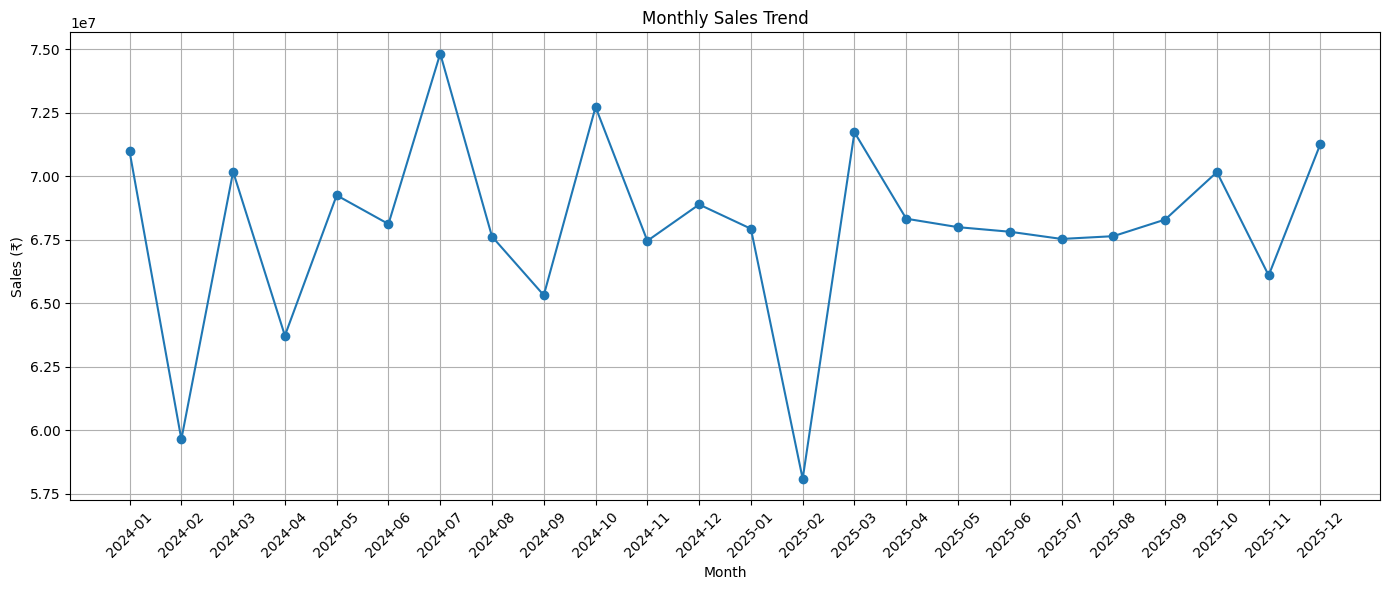

In [51]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly["order_year_month"],
    monthly["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [52]:
# ============================================
# STEP 40: CATEGORY ANALYSIS
# ============================================

category_analysis = (
    df_clean
    .groupby("category")
    .agg(
        Sales=("sales_amount", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique"),
        Quantity=("quantity", "sum")
    )
    .reset_index()
)

category_analysis["Profit_Margin"] = (
    category_analysis["Profit"] /
    category_analysis["Sales"] * 100
)

category_analysis = category_analysis.sort_values(
    "Sales",
    ascending=False
)

display(category_analysis)

,category,Sales,Profit,Orders,Quantity,Profit_Margin
2,Electronics,"1,299,669,644.44","326,152,724.74",14023,24739,25.10
4,Home & Kitchen,"177,423,936.37","44,493,489.87",9004,15964,25.08
3,Fashion,"81,233,947.47","20,269,060.02",12597,22076,24.95
5,Sports,"43,382,624.44","10,858,484.81",4508,7893,25.03
0,Beauty,"19,489,395.79","4,871,099.48",4899,8588,24.99
1,Books,"10,413,135.53","2,579,084.71",4969,8918,24.77


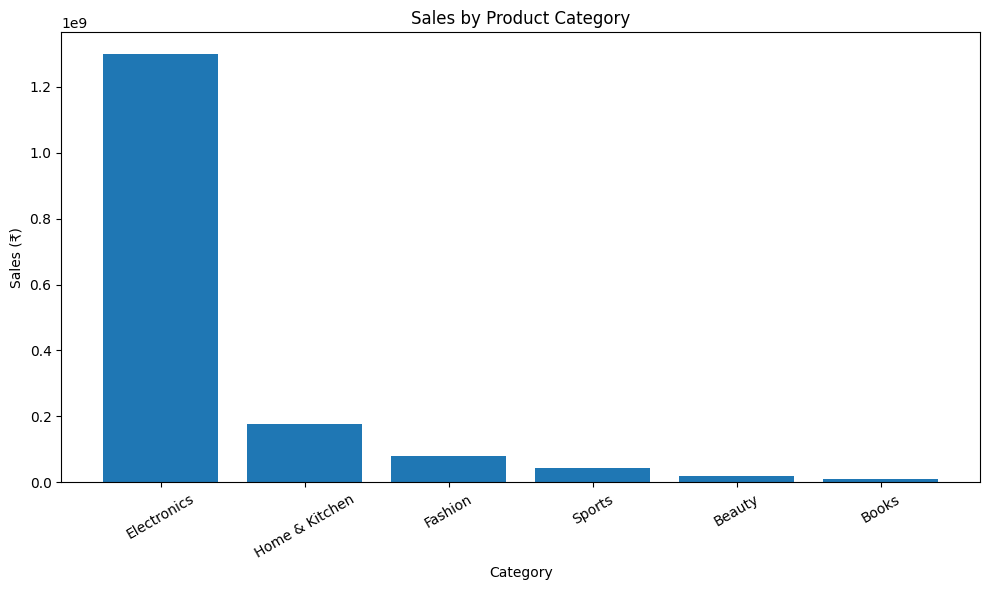

In [53]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_analysis["category"],
    category_analysis["Sales"]
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [54]:
# ============================================
# STEP 42: TOP PRODUCTS
# ============================================

top_products = (
    df_clean
    .groupby(["product_name", "category"])
    .agg(
        Sales=("sales_amount", "sum"),
        Profit=("profit", "sum"),
        Quantity=("quantity", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
    .head(10)
)

display(top_products)

,product_name,category,Sales,Profit,Quantity,Orders
27,Noise Smartwatch,Electronics,"168,902,915.61","41,868,990.19",3171,1804
21,Lenovo Laptop,Electronics,"168,089,192.48","41,825,264.75",3162,1780
3,Boat Wireless Earbuds,Electronics,"166,549,918.42","42,142,508.56",3177,1787
18,HP Laptop,Electronics,"162,858,953.22","41,367,217.64",3097,1763
31,OnePlus Smartphone,Electronics,"159,927,072.05","40,194,819.20",3068,1718
36,Samsung Galaxy Smartphone,Electronics,"158,311,631.36","39,572,923.31",2990,1737
0,Apple iPhone,Electronics,"157,761,763.79","39,706,131.59",3086,1723
39,Sony Headphones,Electronics,"157,268,197.51","39,474,869.50",2988,1711
11,Electric Kettle,Home & Kitchen,"24,344,113.86","6,088,222.61",2155,1214
30,Office Chair,Home & Kitchen,"23,073,412.51","5,751,201.93",2073,1155


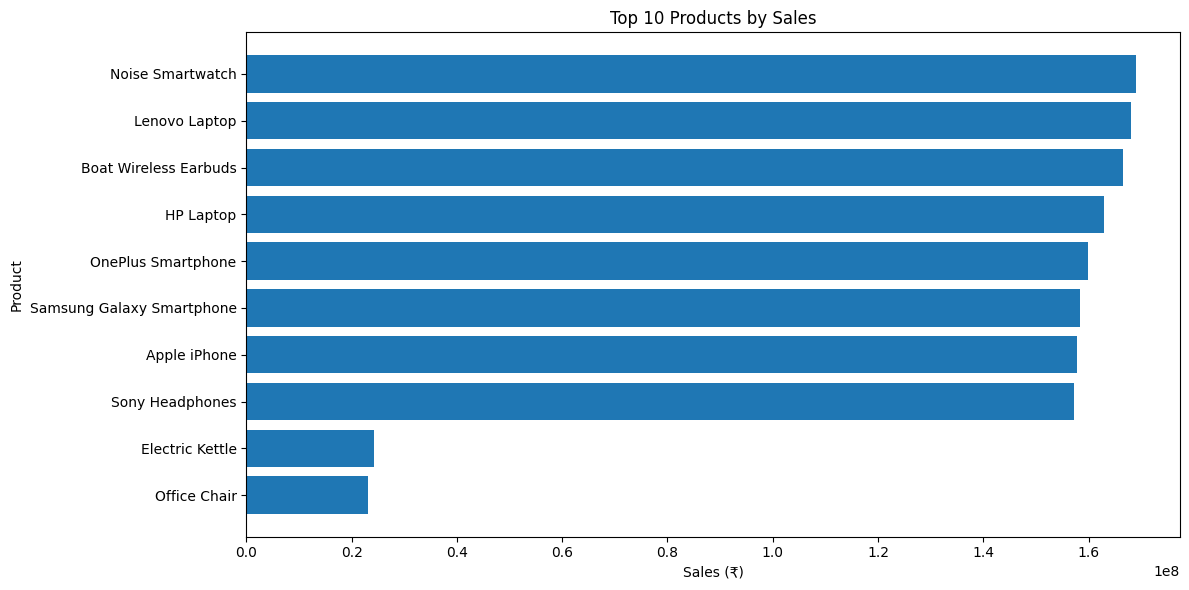

In [55]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products["product_name"],
    top_products["Sales"]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales (₹)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [56]:
# ============================================
# STEP 43: STATE PERFORMANCE
# ============================================

state_analysis = (
    df_clean
    .groupby(["state", "region"])
    .agg(
        Sales=("sales_amount", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_id", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

display(state_analysis)

,state,region,Sales,Profit,Orders,Customers
10,Uttar Pradesh,North,"205,352,983.48","51,219,937.36",6181,1474
5,Maharashtra,West,"203,413,800.91","50,552,567.83",6317,1467
3,Karnataka,South,"145,511,925.10","35,792,817.30",4541,1086
11,West Bengal,East,"141,841,133.51","35,985,116.31",4135,988
8,Tamil Nadu,South,"134,060,482.98","33,517,704.90",4027,974
0,Andhra Pradesh,South,"129,016,462.42","33,168,215.39",4073,961
1,Delhi,North,"125,769,079.27","32,092,132.90",4039,947
2,Gujarat,West,"125,398,705.81","31,490,192.53",3801,931
4,Kerala,South,"118,039,433.95","29,353,707.00",3627,843
7,Rajasthan,West,"117,766,193.78","29,402,147.25",3592,843


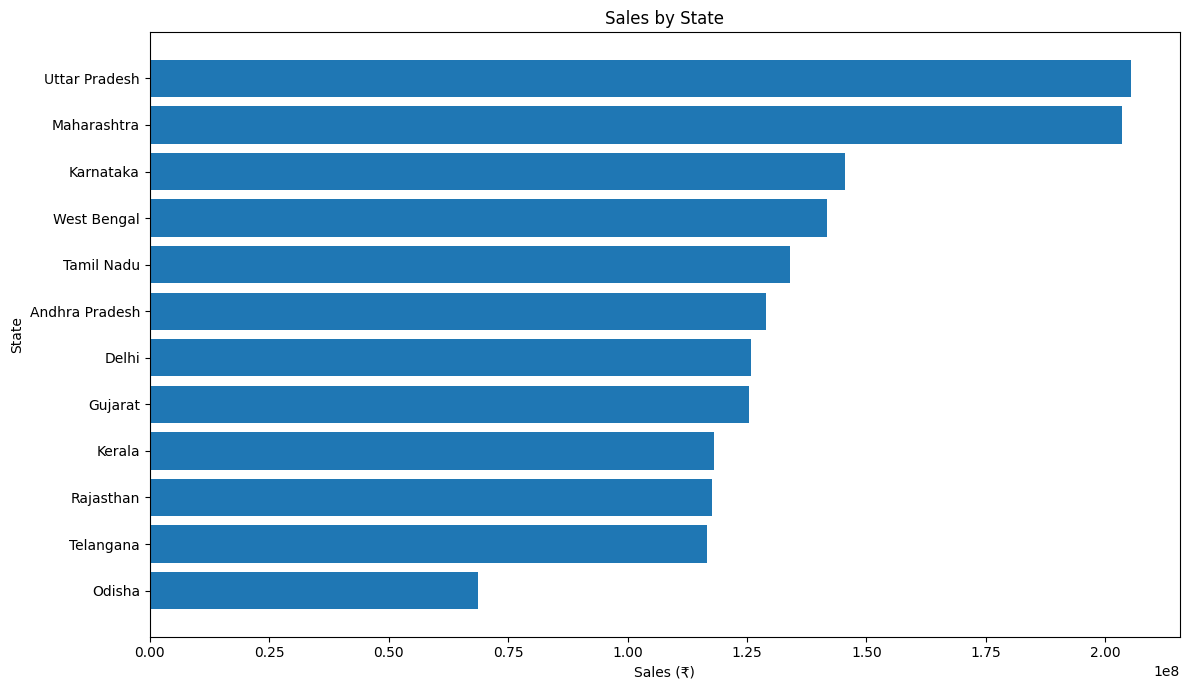

In [57]:
plt.figure(figsize=(12, 7))

plt.barh(
    state_analysis["state"],
    state_analysis["Sales"]
)

plt.title("Sales by State")
plt.xlabel("Sales (₹)")
plt.ylabel("State")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [58]:
# ============================================
# STEP 44: RETURN RATE BY CATEGORY
# ============================================

return_analysis = (
    df_clean
    .groupby("category")
    .agg(
        Orders=("order_id", "nunique"),
        Returned_Orders=("return_flag", "sum"),
        Refunds=("refund_amount", "sum"),
        Return_Cost=("return_cost", "sum")
    )
    .reset_index()
)

return_analysis["Return_Rate"] = (
    return_analysis["Returned_Orders"] /
    return_analysis["Orders"] * 100
)

return_analysis = return_analysis.sort_values(
    "Return_Rate",
    ascending=False
)

display(return_analysis)

,category,Orders,Returned_Orders,Refunds,Return_Cost,Return_Rate
0,Beauty,4899,489,"1,900,625.55","148,700.20",9.98
5,Sports,4508,412,"4,028,435.96","293,788.74",9.14
4,Home & Kitchen,9004,816,"15,383,891.23","1,161,743.96",9.06
2,Electronics,14023,1267,"122,622,811.89","9,213,681.26",9.04
3,Fashion,12597,1131,"7,117,694.86","532,667.68",8.98
1,Books,4969,430,"821,891.00","60,980.90",8.65


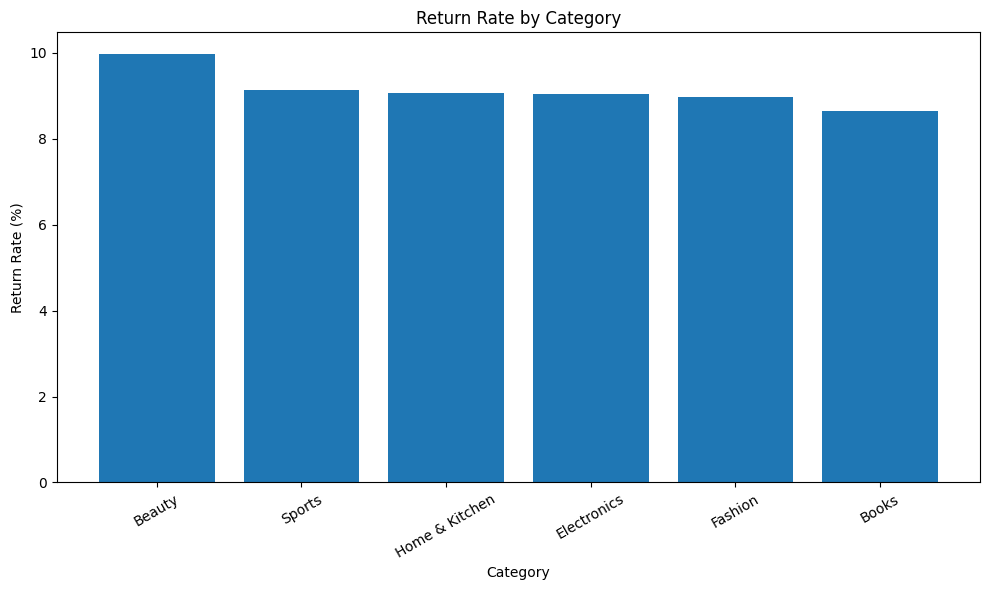

In [59]:
plt.figure(figsize=(10, 6))

plt.bar(
    return_analysis["category"],
    return_analysis["Return_Rate"]
)

plt.title("Return Rate by Category")
plt.xlabel("Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [60]:
# ============================================
# STEP 45: RETURN REASONS
# ============================================

reason_analysis = (
    df_clean[df_clean["return_flag"] == 1]
    .groupby("return_reason")
    .agg(
        Returned_Orders=("order_id", "nunique"),
        Refunds=("refund_amount", "sum")
    )
    .reset_index()
    .sort_values(
        "Returned_Orders",
        ascending=False
    )
)

display(reason_analysis)

,return_reason,Returned_Orders,Refunds
4,Product Quality,914,"30,424,104.59"
5,Size/Fit Issue,855,"28,453,470.19"
1,Damaged Product,697,"22,606,517.72"
0,Changed Mind,661,"24,826,587.89"
6,Wrong Product,529,"18,470,861.72"
2,Late Delivery,476,"14,625,494.07"
3,Other,413,"12,468,314.31"


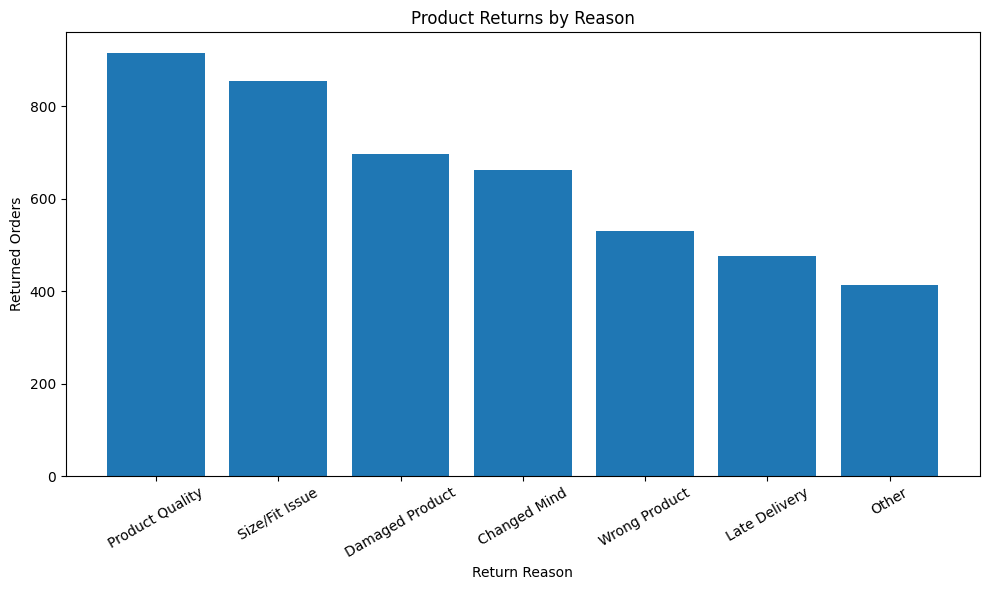

In [61]:
plt.figure(figsize=(10, 6))

plt.bar(
    reason_analysis["return_reason"],
    reason_analysis["Returned_Orders"]
)

plt.title("Product Returns by Reason")
plt.xlabel("Return Reason")
plt.ylabel("Returned Orders")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [62]:
# ============================================
# STEP 46: CUSTOMER RATINGS
# ============================================

rating_analysis = (
    df_clean
    .groupby("customer_rating")
    .agg(
        Orders=("order_id", "nunique"),
        Sales=("sales_amount", "sum")
    )
    .reset_index()
)

display(rating_analysis)

,customer_rating,Orders,Sales
0,1,2500,"84,662,817.64"
1,2,3976,"131,374,804.80"
2,3,8555,"282,397,996.41"
3,4,17413,"560,602,508.37"
4,5,17556,"572,574,556.82"


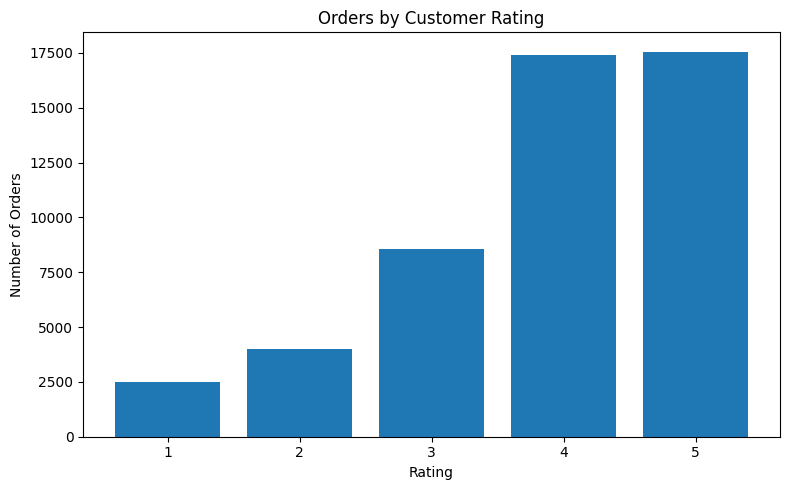

In [63]:
plt.figure(figsize=(8, 5))

plt.bar(
    rating_analysis["customer_rating"].astype(str),
    rating_analysis["Orders"]
)

plt.title("Orders by Customer Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [64]:
# ============================================
# STEP 47: DISCOUNT VS PROFIT
# ============================================

discount_analysis = (
    df_clean
    .groupby("discount_percent")
    .agg(
        Sales=("sales_amount", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

display(discount_analysis)

,discount_percent,Sales,Profit,Orders
0,0,"188,617,350.81","48,424,059.19",5031
1,5,"346,850,045.78","86,626,909.35",9989
2,10,"417,014,185.26","105,107,180.21",12466
3,15,"319,790,631.50","79,474,894.17",10001
4,20,"179,968,329.55","45,216,434.90",5920
5,25,"111,333,694.67","27,523,928.22",4096
6,30,"68,038,446.46","16,850,537.59",2497


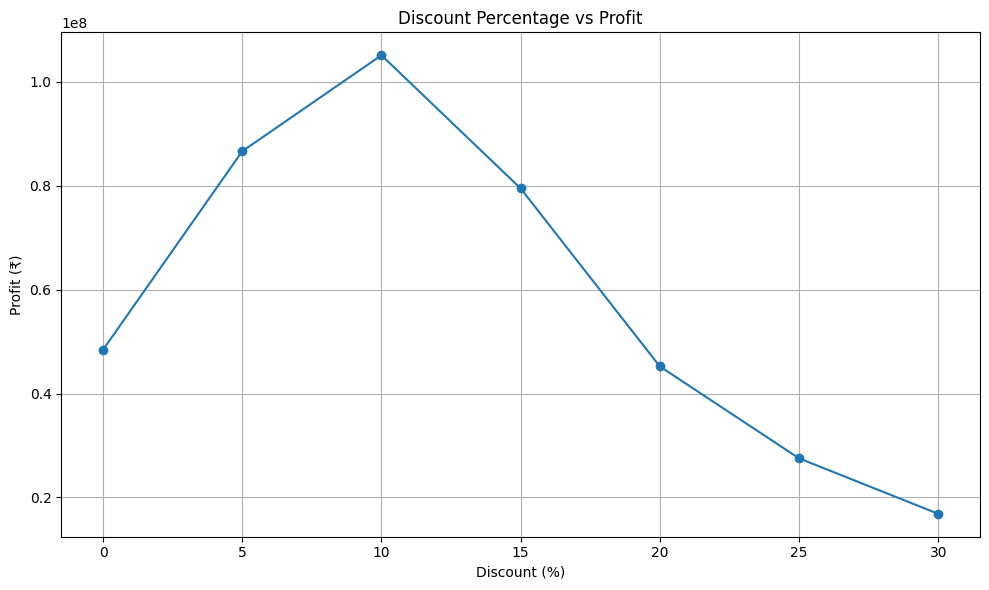

In [65]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis["discount_percent"],
    discount_analysis["Profit"],
    marker="o"
)

plt.title("Discount Percentage vs Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Profit (₹)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [66]:
# ============================================
# STEP 48: CUSTOMER PURCHASE FREQUENCY
# ============================================

customer_orders = (
    df_clean
    .groupby("customer_id")
    .agg(
        Orders=("order_id", "nunique"),
        Sales=("sales_amount", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
)

display(customer_orders.head())

,customer_id,Orders,Sales,Profit
0,CUST00001,7,"59,864.40","16,949.24"
1,CUST00002,6,"18,174.73","3,798.63"
2,CUST00003,3,"52,168.51","17,755.36"
3,CUST00004,4,"33,910.72","9,266.30"
4,CUST00005,5,"88,126.07","26,214.20"


In [67]:
customer_orders["Customer_Type"] = np.select(
    [
        customer_orders["Orders"] == 1,
        customer_orders["Orders"].between(2, 3),
        customer_orders["Orders"] >= 4
    ],
    [
        "One-Time",
        "Repeat",
        "Loyal"
    ],
    default="Other"
)

customer_type_summary = (
    customer_orders
    .groupby("Customer_Type")
    .agg(
        Customers=("customer_id", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

display(customer_type_summary)

,Customer_Type,Customers,Sales,Profit
0,Loyal,7137,"1,272,649,849.03","318,968,593.02"
1,One-Time,783,"27,514,806.37","7,113,924.00"
2,Repeat,3917,"331,448,028.63","83,141,426.61"


In [68]:
# ============================================
# STEP 51: CUSTOMER DIMENSION
# ============================================

customer_table = (
    df_clean[
        [
            "customer_id",
            "customer_name",
            "age",
            "gender"
        ]
    ]
    .drop_duplicates("customer_id")
    .reset_index(drop=True)
)

print("Customer dimension created!")
print("Customers:", len(customer_table))

display(customer_table.head())

Customer dimension created!
Customers: 11837


,customer_id,customer_name,age,gender
0,CUST01269,Samesh Mann,52,Male
1,CUST09683,Yashoda Gandhi,18,Male
2,CUST05562,Anika Sani,23,Female
3,CUST06046,Jeremiah Mistry,22,Female
4,CUST11272,Mahika Ahuja,20,Male


In [69]:
# ============================================
# STEP 50: DATE DIMENSION
# ============================================

date_table = (
    df_clean[["order_date"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

date_table["date_id"] = date_table.index + 1
date_table["order_year"] = date_table["order_date"].dt.year
date_table["order_month"] = date_table["order_date"].dt.month
date_table["order_month_name"] = date_table["order_date"].dt.strftime("%B")
date_table["order_day"] = date_table["order_date"].dt.day
date_table["order_day_name"] = date_table["order_date"].dt.day_name()
date_table["order_quarter"] = date_table["order_date"].dt.quarter
date_table["is_weekend"] = date_table["order_date"].dt.dayofweek.isin([5, 6]).astype(int)

date_table = date_table[[
    "date_id",
    "order_date",
    "order_day",
    "order_day_name",
    "order_month",
    "order_month_name",
    "order_quarter",
    "order_year",
    "is_weekend"
]].sort_values("order_date").reset_index(drop=True)

print("Date dimension created!")
print("Unique Dates:", len(date_table))

display(date_table.head())

Date dimension created!
Unique Dates: 731


,date_id,order_date,order_day,order_day_name,order_month,order_month_name,order_quarter,order_year,is_weekend
0,341,2024-01-01,1,Monday,1,January,1,2024,0
1,277,2024-01-02,2,Tuesday,1,January,1,2024,0
2,655,2024-01-03,3,Wednesday,1,January,1,2024,0
3,513,2024-01-04,4,Thursday,1,January,1,2024,0
4,333,2024-01-05,5,Friday,1,January,1,2024,0


In [70]:
# ============================================
# STEP 52: PRODUCT DIMENSION
# ============================================

product_table = (
    df_clean[
        [
            "product_id",
            "product_name",
            "category",
            "sub_category"
        ]
    ]
    .drop_duplicates("product_id")
    .reset_index(drop=True)
)

print("Product dimension created!")
print("Products:", len(product_table))

display(product_table.head())

Product dimension created!
Products: 48


,product_id,product_name,category,sub_category
0,PROD0001,Football,Sports,Fitness
1,PROD0002,Non-Stick Cookware,Home & Kitchen,Decor
2,PROD0003,Formal Shoes,Fashion,Women
3,PROD0004,Boat Wireless Earbuds,Electronics,Smartphones
4,PROD0005,Sunscreen,Beauty,Fragrance


In [71]:
# ============================================
# STEP 53: GEOGRAPHY DIMENSION
# ============================================

geography_table = (
    df_clean[
        [
            "city",
            "state",
            "region"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Create Geography ID
geography_table.insert(
    0,
    "geography_id",
    range(1, len(geography_table) + 1)
)

print("Geography dimension created!")
print("Locations:", len(geography_table))

display(geography_table.head())

Geography dimension created!
Locations: 41


,geography_id,city,state,region
0,1,Tirupati,Andhra Pradesh,South
1,2,Warangal,Telangana,South
2,3,Nagpur,Maharashtra,West
3,4,Durgapur,West Bengal,East
4,5,Jaipur,Rajasthan,West


In [72]:
# ============================================
# STEP 54: ADD GEOGRAPHY KEY TO FACT TABLE
# ============================================

df_clean = df_clean.merge(
    geography_table,
    on=["city", "state", "region"],
    how="left"
)

print("Geography keys added.")

display(
    df_clean[
        [
            "order_id",
            "city",
            "state",
            "region",
            "geography_id"
        ]
    ].head()
)

Geography keys added.


,order_id,city,state,region,geography_id
0,ORD000001,Tirupati,Andhra Pradesh,South,1
1,ORD000002,Warangal,Telangana,South,2
2,ORD000003,Nagpur,Maharashtra,West,3
3,ORD000004,Durgapur,West Bengal,East,4
4,ORD000005,Jaipur,Rajasthan,West,5


In [73]:
# ============================================
# STEP 55: CREATE FACT ORDERS
# ============================================

fact_orders = df_clean[
    [
        "order_id",
        "customer_id",
        "product_id",
        "geography_id",
        "order_date",

        "quantity",
        "unit_price",
        "discount_percent",
        "gross_amount",
        "discount_amount",
        "sales_amount",
        "cost_amount",
        "profit",

        "payment_method",
        "order_status",
        "delivery_days",

        "return_flag",
        "return_date",
        "return_reason",
        "refund_amount",
        "return_cost",

        "customer_rating",

        "net_sales",
        "net_profit"
    ]
].copy()

print("Fact Orders created!")
print("Rows:", len(fact_orders))
print("Columns:", len(fact_orders.columns))

display(fact_orders.head())

Fact Orders created!
Rows: 50000
Columns: 24


,order_id,customer_id,product_id,geography_id,order_date,quantity,unit_price,discount_percent,gross_amount,discount_amount,sales_amount,cost_amount,profit,payment_method,order_status,delivery_days,return_flag,return_date,return_reason,refund_amount,return_cost,customer_rating,net_sales,net_profit
0,ORD000001,CUST01269,PROD0001,1,2024-06-19,2,"10,443.45",20,"20,886.90","4,177.38","16,709.52","11,491.18","5,218.34",Cash on Delivery,Delivered,5,0,NaT,NaN,0.00,0.00,3,"16,709.52","5,218.34"
1,ORD000002,CUST09683,PROD0002,2,2025-04-18,2,"17,322.29",5,"34,644.58","1,732.23","32,912.35","24,429.94","8,482.41",Credit Card,Delivered,5,0,NaT,NaN,0.00,0.00,4,"32,912.35","8,482.41"
2,ORD000003,CUST05562,PROD0003,3,2025-02-25,1,983.62,20,983.62,196.72,786.90,693.81,93.09,Debit Card,Delivered,2,0,NaT,NaN,0.00,0.00,5,786.90,93.09
3,ORD000004,CUST06046,PROD0004,4,2025-06-16,2,"87,143.38",15,"174,286.76","26,143.01","148,143.75","126,315.99","21,827.76",Wallet,Delivered,4,0,NaT,NaN,0.00,0.00,5,"148,143.75","21,827.76"
4,ORD000005,CUST11272,PROD0005,5,2024-10-12,1,"2,093.62",20,"2,093.62",418.72,"1,674.90","1,119.94",554.96,Credit Card,Delivered,3,0,NaT,NaN,0.00,0.00,5,"1,674.90",554.96


In [74]:
# ============================================
# STEP 56: CHECK POWER BI TABLES
# ============================================

print("FACT TABLE")
print("=" * 50)
print(fact_orders.shape)

print("\nCUSTOMER TABLE")
print("=" * 50)
print(customer_table.shape)

print("\nPRODUCT TABLE")
print("=" * 50)
print(product_table.shape)

print("\nGEOGRAPHY TABLE")
print("=" * 50)
print(geography_table.shape)

print("\nDATE TABLE")
print("=" * 50)
print(date_table.shape)

FACT TABLE
(50000, 24)

CUSTOMER TABLE
(11837, 4)

PRODUCT TABLE
(48, 4)

GEOGRAPHY TABLE
(41, 4)

DATE TABLE
(731, 9)


In [75]:
# ============================================
# STEP 57: EXPORT POWER BI DATASETS
# ============================================

import os

os.makedirs("powerbi_data", exist_ok=True)

fact_orders.to_csv(
    "powerbi_data/fact_orders.csv",
    index=False
)

customer_table.to_csv(
    "powerbi_data/dim_customer.csv",
    index=False
)

product_table.to_csv(
    "powerbi_data/dim_product.csv",
    index=False
)

geography_table.to_csv(
    "powerbi_data/dim_geography.csv",
    index=False
)

date_table.to_csv(
    "powerbi_data/dim_date.csv",
    index=False
)

print("✅ All Power BI datasets exported!")

✅ All Power BI datasets exported!


In [76]:
# ============================================
# STEP 57.1: ZIP POWER BI DATA
# ============================================

import shutil

shutil.make_archive(
    "flipkart_powerbi_data",
    "zip",
    "powerbi_data"
)

print("✅ ZIP file created!")

✅ ZIP file created!


In [77]:
from google.colab import files

files.download("flipkart_powerbi_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [83]:
!pip install -q pyspark apache-airflow pytest
!java -version

import os
os.makedirs("/content/ecommerce-etl-pipeline/etl", exist_ok=True)
os.makedirs("/content/ecommerce-etl-pipeline/dags", exist_ok=True)
os.makedirs("/content/ecommerce-etl-pipeline/tests", exist_ok=True)
os.makedirs("/content/ecommerce-etl-pipeline/data/raw", exist_ok=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
[0.025s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.025s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [84]:
import pandas as pd, numpy as np
n = 5000
df = pd.DataFrame({
    "order_id": np.random.randint(1, 4800, n),
    "order_date": pd.date_range("2026-01-01", periods=n, freq="h").strftime("%Y-%m-%d"),
    "amount": np.round(np.random.uniform(-20, 500, n), 2),
})
df.to_csv("/content/ecommerce-etl-pipeline/data/raw/orders.csv", index=False)

In [87]:
%%writefile /content/ecommerce-etl-pipeline/etl/transform.py
from pyspark.sql import SparkSession, functions as F

def get_spark():
    return (SparkSession.builder
            .appName("ecommerce_etl")
            .master("local[*]")
            .getOrCreate())

def extract(spark, path):
    return spark.read.csv(path, header=True, inferSchema=True)

def transform(df):
    df = df.dropDuplicates(["order_id"])
    df = df.filter(F.col("order_id").isNotNull() & (F.col("amount") > 0))
    df = df.withColumn("order_date", F.to_date("order_date"))
    df = df.withColumn("order_month", F.date_format("order_date", "yyyy-MM"))
    return df

def reconcile(raw_df, clean_df):
    raw_count = raw_df.count()
    clean_count = clean_df.count()
    null_ids = clean_df.filter(F.col("order_id").isNull()).count()
    dupes = clean_count - clean_df.dropDuplicates(["order_id"]).count()
    assert null_ids == 0, "Null order_id found"
    assert dupes == 0, "Duplicate order_id found"
    assert clean_count <= raw_count, "Clean rows exceed raw rows"
    return {"raw": raw_count, "clean": clean_count,
            "rejected": raw_count - clean_count}

def load(df, out_dir):
    df.write.mode("overwrite").partitionBy("order_month").parquet(out_dir)

Overwriting /content/ecommerce-etl-pipeline/etl/transform.py


In [88]:
%%writefile /content/ecommerce-etl-pipeline/dags/ecommerce_etl_dag.py
import sys
from datetime import datetime, timedelta
from airflow import DAG
from airflow.operators.python import PythonOperator

BASE = "/content/ecommerce-etl-pipeline"
sys.path.append(BASE)
from etl.transform import get_spark, extract, transform, reconcile, load

RAW = f"{BASE}/data/raw/orders.csv"
STAGING = f"{BASE}/data/staging"
CURATED = f"{BASE}/data/curated"

def run_transform():
    spark = get_spark()
    clean = transform(extract(spark, RAW))
    clean.write.mode("overwrite").parquet(STAGING)

def run_validation():
    spark = get_spark()
    raw = extract(spark, RAW)
    clean = spark.read.parquet(STAGING)
    print("Reconciliation:", reconcile(raw, clean))

def run_load():
    spark = get_spark()
    load(spark.read.parquet(STAGING), CURATED)

default_args = {"retries": 2, "retry_delay": timedelta(minutes=2)}

with DAG("ecommerce_etl", start_date=datetime(2026, 1, 1),
         schedule="@daily", catchup=False,
         default_args=default_args) as dag:
    t1 = PythonOperator(task_id="transform", python_callable=run_transform)
    t2 = PythonOperator(task_id="validate", python_callable=run_validation)
    t3 = PythonOperator(task_id="load", python_callable=run_load)
    t1 >> t2 >> t3

Overwriting /content/ecommerce-etl-pipeline/dags/ecommerce_etl_dag.py


In [89]:
%%writefile /content/ecommerce-etl-pipeline/tests/test_transform.py
from etl.transform import get_spark, transform

def test_removes_duplicates_and_bad_amounts():
    spark = get_spark()
    df = spark.createDataFrame(
        [(1, "2026-01-05", 100.0), (1, "2026-01-05", 100.0),
         (2, "2026-01-06", -5.0)],
        ["order_id", "order_date", "amount"])
    assert transform(df).count() == 1

Writing /content/ecommerce-etl-pipeline/tests/test_transform.py


In [90]:
!touch /content/ecommerce-etl-pipeline/etl/__init__.py
!cd /content/ecommerce-etl-pipeline && python -m pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/ecommerce-etl-pipeline
plugins: Faker-40.63.0, platformdirs-4.14.3, anyio-4.16.0, typeguard-4.6.0, langsmith-0.14.17
collected 1 item                                                               

tests/test_transform.py::test_removes_duplicates_and_bad_amounts PASSED  [100%]

============================== 1 passed in 27.05s ==============================


In [91]:
import os
os.environ["AIRFLOW_HOME"] = "/content/airflow"
os.environ["AIRFLOW__CORE__DAGS_FOLDER"] = "/content/ecommerce-etl-pipeline/dags"
os.environ["AIRFLOW__CORE__LOAD_EXAMPLES"] = "False"

!airflow db migrate
!airflow dags test ecommerce_etl 2026-11-24

2026-11-24T04:58:55.147744Z [info     ] Performing upgrade to the metadata database [airflow.cli.commands.db_command] loc=db_command.py:134 url=sqlite:////content/airflow/airflow.db
2026-11-24T04:58:56.933855Z [info     ] Context impl SQLiteImpl.       [alembic.runtime.migration] loc=migration.py:205
2026-11-24T04:58:56.934152Z [info     ] Will assume non-transactional DDL. [alembic.runtime.migration] loc=migration.py:208
2026-11-24T04:58:58.362344Z [info     ] Context impl SQLiteImpl.       [alembic.runtime.migration] loc=migration.py:205
2026-11-24T04:58:58.362606Z [info     ] Will assume non-transactional DDL. [alembic.runtime.migration] loc=migration.py:208
2026-11-24T04:58:58.363189Z [info     ] Creating Airflow database tables from the ORM [airflow.utils.db] loc=db.py:750
2026-11-24T04:58:58.363379Z [info     ] Creating global lock context   [airflow.utils.db] loc=db.py:731
2026-11-24T04:58:58.363558Z [info     ] Pool status: Pool size: 5  Connections in pool: 0 Current Overflow:

In [92]:
import os
for p in ["/content/ecommerce-etl-pipeline/data/staging",
          "/content/ecommerce-etl-pipeline/data/curated"]:
    print(p, "->", os.listdir(p) if os.path.exists(p) else "MISSING")

/content/ecommerce-etl-pipeline/data/staging -> ['.part-00000-27176883-9e70-45e1-8a50-1a3f316e1c49-c000.snappy.parquet.crc', '._SUCCESS.crc', 'part-00000-27176883-9e70-45e1-8a50-1a3f316e1c49-c000.snappy.parquet', '_SUCCESS']
/content/ecommerce-etl-pipeline/data/curated -> ['._SUCCESS.crc', 'order_month=2026-07', '_SUCCESS', 'order_month=2026-06', 'order_month=2026-05', 'order_month=2026-02', 'order_month=2026-04', 'order_month=2026-01', 'order_month=2026-03']


In [93]:
!airflow dags test ecommerce_etl 2026-11-24 2>&1 | grep -E "Reconciliation|state=|success|failed|Task|DagRun"

2026-11-24T05:01:17.946637Z [info     ] get next_dagrun_info_v2        [airflow.serialization.definitions.dag] last_automated_run_info=None loc=dag.py:491 next_info=DagRunInfo(run_after=DateTime(2026, 11, 24, 0, 0, 0, tzinfo=Timezone('UTC')), data_interval=DataInterval(start=DateTime(2026, 11, 24, 0, 0, 0, tzinfo=Timezone('UTC')), end=DateTime(2026, 11, 24, 0, 0, 0, tzinfo=Timezone('UTC'))), partition_date=None, partition_key=None)
2026-11-24T05:01:18.954351Z [info     ] get next_dagrun_info_v2        [airflow.serialization.definitions.dag] last_automated_run_info=None loc=dag.py:491 next_info=DagRunInfo(run_after=DateTime(2026, 11, 24, 0, 0, 0, tzinfo=Timezone('UTC')), data_interval=DataInterval(start=DateTime(2026, 11, 24, 0, 0, 0, tzinfo=Timezone('UTC')), end=DateTime(2026, 11, 24, 0, 0, 0, tzinfo=Timezone('UTC'))), partition_date=None, partition_key=None)
2026-11-24T05:01:19.081668Z [info     ] Created dag run.               [airflow.models.dagrun] dagrun=<DagRun ecommerce_etl @ 20

In [94]:
import os, sys
os.environ["AIRFLOW_HOME"] = "/content/airflow"
os.environ["AIRFLOW__CORE__LOAD_EXAMPLES"] = "False"
sys.path.append("/content/ecommerce-etl-pipeline/dags")
from ecommerce_etl_dag import dag
dag.test()

2026-11-24T05:02:44.218144Z [warning  ] The `airflow.operators.python.PythonOperator` attribute is deprecated. Please use `'airflow.providers.standard.operators.python.PythonOperator'`. [py.warnings] category=DeprecatedImportWarning filename=/content/ecommerce-etl-pipeline/dags/ecommerce_etl_dag.py lineno=4
2026-11-24T05:02:45.378821Z [info     ] DAG bundles loaded: dags-folder [airflow.dag_processing.bundles.manager.DagBundlesManager] loc=manager.py:344
2026-11-24T05:02:45.393389Z [info     ] Filling up the DagBag from /content/ecommerce-etl-pipeline/dags [airflow.dag_processing.dagbag.BundleDagBag] loc=dagbag.py:583
2026-11-24T05:02:45.400330Z [warning  ] The `airflow.operators.python.PythonOperator` attribute is deprecated. Please use `'airflow.providers.standard.operators.python.PythonOperator'`. [py.warnings] category=UserWarning filename=/content/ecommerce-etl-pipeline/dags/ecommerce_etl_dag.py lineno=4
2026-11-24T05:02:45.421348Z [info     ] Bulk-writing dags to db        [airfl

<DagRun ecommerce_etl @ 2026-11-24 05:02:45.125872+00:00: manual__2026-11-24T05:02:45.377421+00:00, state:success, queued_at: None. run_type: manual>